# Government Service Assistant: Architecture and Evaluation

This notebook documents the prototype architecture and use cases, then reproduces the saved benchmark graphs for multilingual-e5-base, BGE-M3, LaBSE, and three-model rank fusion.

## How to read the results

The benchmark uses a deterministic sample of 250 generated test questions. Scheme-field accuracy measures whether the top retrieved passage belongs to the expected scheme and field. Macro precision and recall treat each scheme-field pair as a class. Retrieval Recall@k measures whether the expected passage appears among the top k retrieved passages. Rank-fusion accuracy and coverage come from the recorded benchmark output.

These are retrieval/classification results, not human-reviewed answer correctness or proof that scheme information is current. Scheme facts need official-source review and dates before deployment claims can be made.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Ellipse, FancyArrowPatch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "evaluation"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
MODELS = ["multilingual-e5-base", "BGE-M3", "LaBSE"]
plt.rcParams.update({"figure.dpi": 130, "font.size": 9, "axes.titleweight": "bold"})
print(f"Project: {ROOT}")
print(f"Evaluation data: {DATA}")

## System architecture

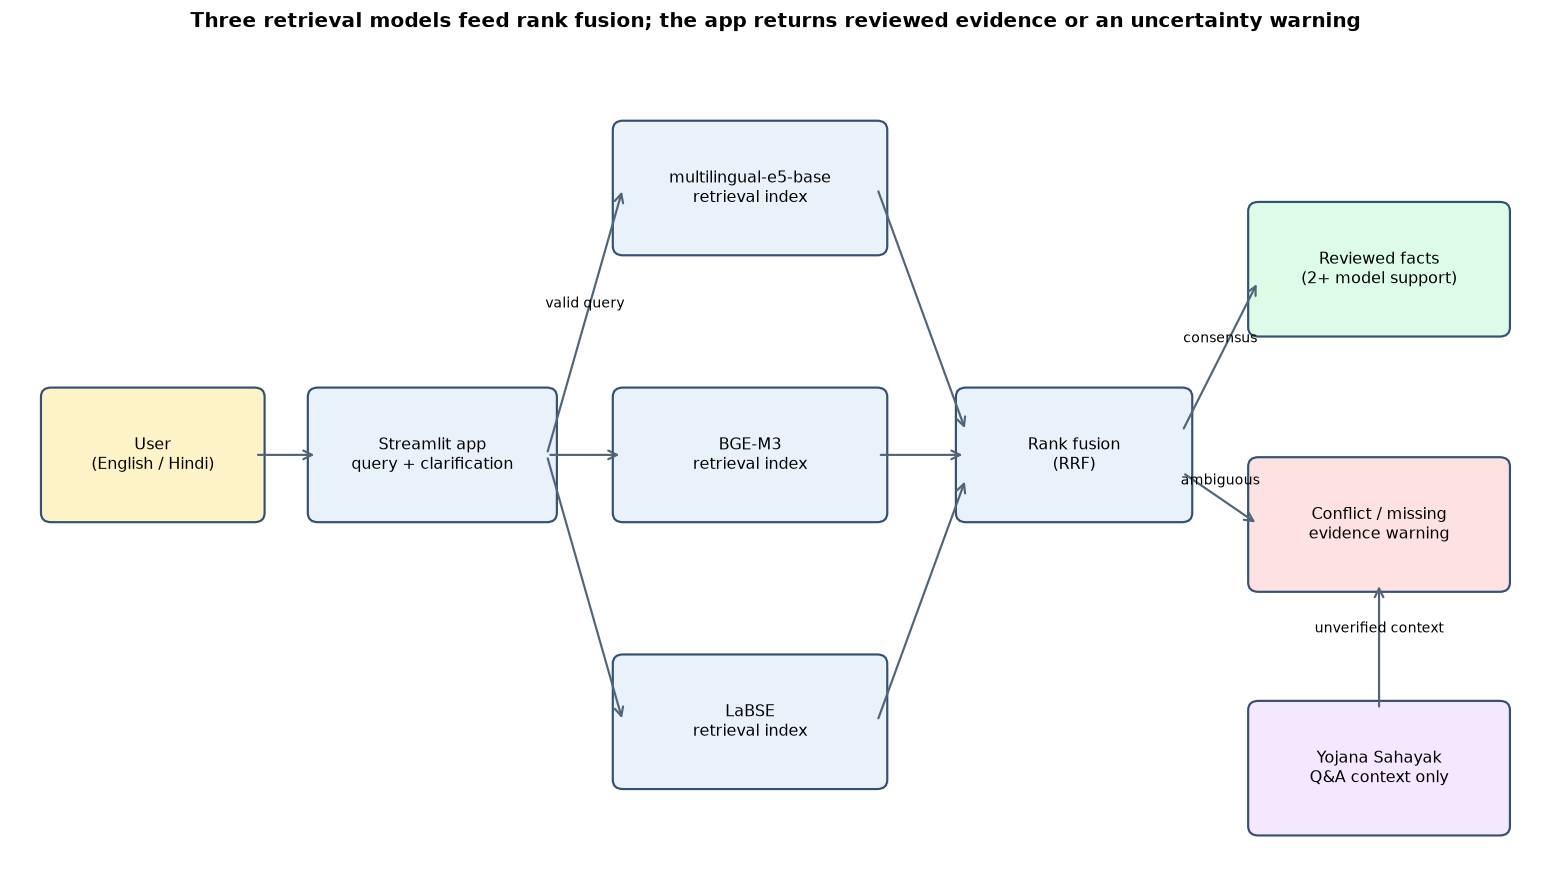

In [2]:
fig, ax = plt.subplots(figsize=(12, 6.8))
ax.set(xlim=(0,12), ylim=(0,7)); ax.axis("off")
def box(x,y,w,h,label,color="#e9f1fb"):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=.08",fc=color,ec="#355070",lw=1.2))
    ax.text(x+w/2,y+h/2,label,ha="center",va="center",fontsize=9)
def arrow(x1,y1,x2,y2,label=""):
    ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2),arrowstyle="->",mutation_scale=12,color="#516579",lw=1.2))
    if label: ax.text((x1+x2)/2,(y1+y2)/2+.12,label,ha="center",fontsize=8)
box(.3,3,1.6,1,"User\n(English / Hindi)","#fef3c7")
box(2.4,3,1.8,1,"Streamlit app\nquery + clarification")
box(4.8,5.3,2,1,"multilingual-e5-base\nretrieval index")
box(4.8,3,2,1,"BGE-M3\nretrieval index")
box(4.8,.7,2,1,"LaBSE\nretrieval index")
box(7.5,3,1.7,1,"Rank fusion\n(RRF)")
box(9.8,4.6,1.9,1,"Reviewed facts\n(2+ model support)","#dcfce7")
box(9.8,2.4,1.9,1,"Conflict / missing\nevidence warning","#fee2e2")
box(9.8,.3,1.9,1,"Yojana Sahayak\nQ&A context only","#f3e8ff")
arrow(1.9,3.5,2.4,3.5); arrow(4.2,3.5,4.8,5.8,"valid query"); arrow(4.2,3.5,4.8,3.5); arrow(4.2,3.5,4.8,1.2)
arrow(6.8,5.8,7.5,3.7); arrow(6.8,3.5,7.5,3.5); arrow(6.8,1.2,7.5,3.3)
arrow(9.2,3.7,9.8,5,"consensus"); arrow(9.2,3.35,9.8,2.9,"ambiguous"); arrow(10.75,1.3,10.75,2.4,"unverified context")
ax.set_title("Three retrieval models feed rank fusion; the app returns reviewed evidence or an uncertainty warning",pad=12)
fig.tight_layout(); fig.savefig(REPORTS/"system_architecture.png",bbox_inches="tight"); plt.show()

## Use case diagram

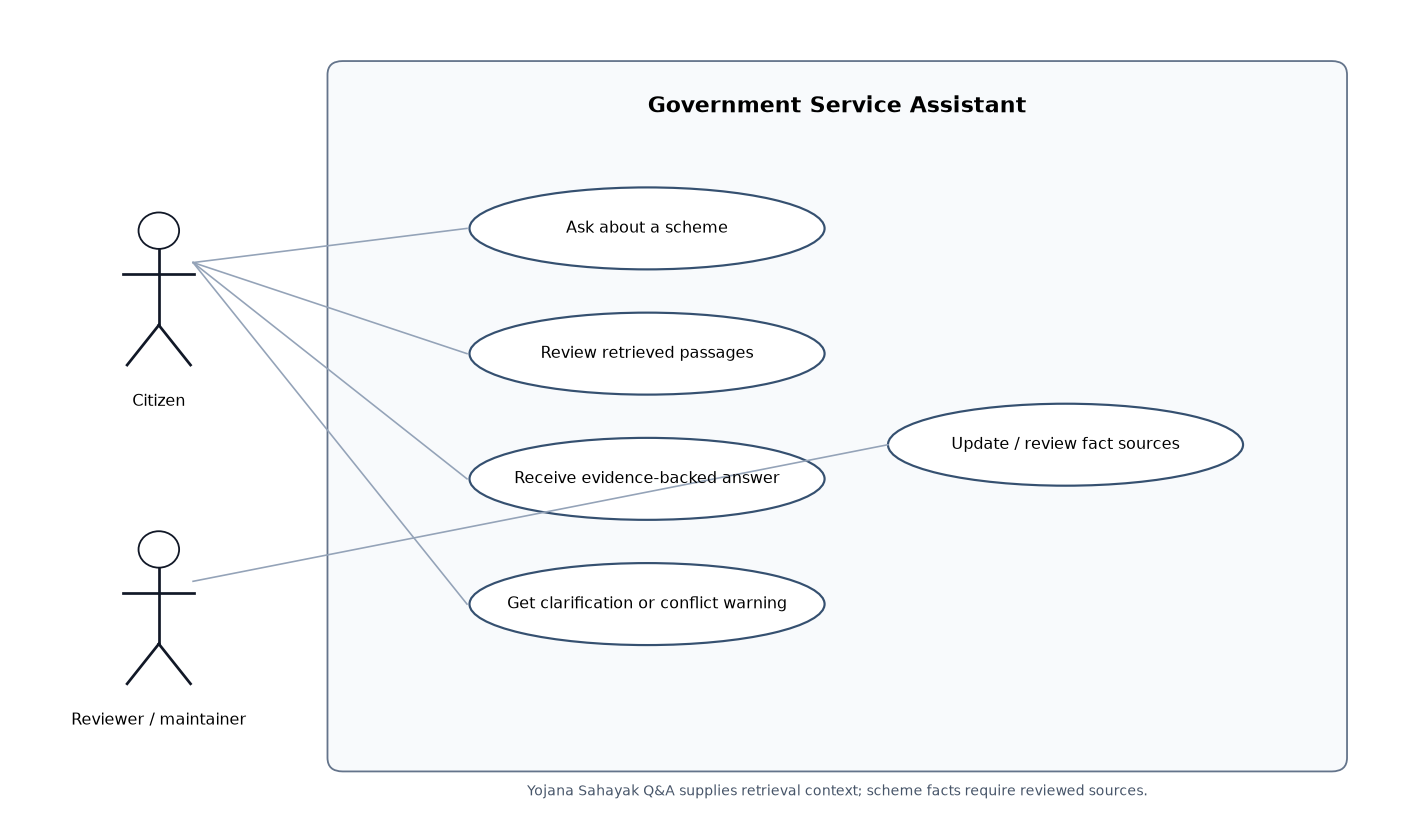

In [3]:
fig, ax = plt.subplots(figsize=(11,6.4)); ax.set(xlim=(0,11),ylim=(0,7)); ax.axis("off")
ax.add_patch(FancyBboxPatch((2.6,.45),7.8,6,boxstyle="round,pad=.12",fc="#f8fafc",ec="#64748b"))
ax.text(6.5,6.12,"Government Service Assistant",ha="center",fontsize=12,fontweight="bold")
def usecase(x,y,label):
    ax.add_patch(Ellipse((x,y),2.8,.72,fc="white",ec="#355070",lw=1.2)); ax.text(x,y,label,ha="center",va="center",fontsize=9)
def actor(x,y,label):
    ax.add_patch(Ellipse((x,y+.48),.32,.32,fc="white",ec="#111827")); ax.plot([x,x],[y+.32,y-.35],color="#111827"); ax.plot([x-.28,x+.28],[y+.1,y+.1],color="#111827"); ax.plot([x,x-.25],[y-.35,y-.7],color="#111827"); ax.plot([x,x+.25],[y-.35,y-.7],color="#111827"); ax.text(x,y-.95,label,ha="center",va="top",fontsize=9)
actor(1.15,4.6,"Citizen"); actor(1.15,1.8,"Reviewer / maintainer")
for y,label in [(5.1,"Ask about a scheme"),(4,"Review retrieved passages"),(2.9,"Receive evidence-backed answer"),(1.8,"Get clarification or conflict warning")]: usecase(5,y,label)
usecase(8.3,3.2,"Update / review fact sources")
for y in [5.1,4,2.9,1.8]: ax.plot([1.42,3.58],[4.8,y],color="#94a3b8",lw=.9)
ax.plot([1.42,6.9],[2,3.2],color="#94a3b8",lw=.9)
ax.text(6.5,.12,"Yojana Sahayak Q&A supplies retrieval context; scheme facts require reviewed sources.",ha="center",fontsize=8,color="#475569")
fig.tight_layout(); fig.savefig(REPORTS/"use_case.png",bbox_inches="tight"); plt.show()

## Reproduce the metric table

In [4]:
questions = pd.read_csv(DATA/"test_questions.csv",keep_default_na=False).sample(250,random_state=24).reset_index(drop=True)
details = pd.read_csv(DATA/"model_comparison_details.csv",keep_default_na=False)
retrieval = pd.read_csv(DATA/"model_comparison.csv",keep_default_na=False)
from sklearn.metrics import precision_recall_fscore_support
rows=[]
for model in MODELS:
    result=details[details.model.eq(model)].copy(); result["question_id"]=pd.to_numeric(result.question_id); result=result.sort_values("question_id")
    if len(result)!=len(questions): raise ValueError(f"Expected {len(questions)} rows for {model}, found {len(result)}")
    truth=(questions.scheme_id.astype(str)+"|"+questions.field.astype(str)).tolist()
    predicted=(result.top1_scheme_id.astype(str)+"|"+result.top1_field.astype(str)).tolist()
    labels=sorted(set(truth)|set(predicted))
    p,r,f1,_=precision_recall_fscore_support(truth,predicted,labels=labels,average="macro",zero_division=0)
    rr=retrieval[retrieval.setup.eq(model)].iloc[0]
    rows.append({"model":model,"queries":len(questions),"scheme_field_accuracy":sum(a==b for a,b in zip(truth,predicted))/len(truth),"macro_precision":p,"macro_recall":r,"macro_f1":f1,"retrieval_recall_at_1":float(rr.recall_at_1),"retrieval_recall_at_5":float(rr.recall_at_5)})
metrics=pd.DataFrame(rows)
ensemble=retrieval[retrieval.setup.str.contains("RRF",case=False)].iloc[0]
metrics.round(3)

model,queries,scheme_field_accuracy,macro_precision,macro_recall,macro_f1,retrieval_recall_at_1,retrieval_recall_at_5
multilingual-e5-base,250,0.392,0.251,0.251,0.250,0.348,0.728
BGE-M3,250,0.624,0.462,0.462,0.460,0.548,0.832
LaBSE,250,0.332,0.201,0.206,0.202,0.228,0.444


### Metric definitions

- **Scheme-field accuracy:** share of queries where the top passage has the expected scheme and field.
- **Macro precision / recall:** calculate each scheme-field class score, then average classes equally; absent predicted classes receive zero.
- **Retrieval Recall@k:** share of queries with the expected evidence passage in the top k.
- **Ensemble accuracy / coverage:** recorded rank-fusion benchmark values; coverage is the share where a response was selected.

## Accuracy, precision, recall, and retrieval graphs

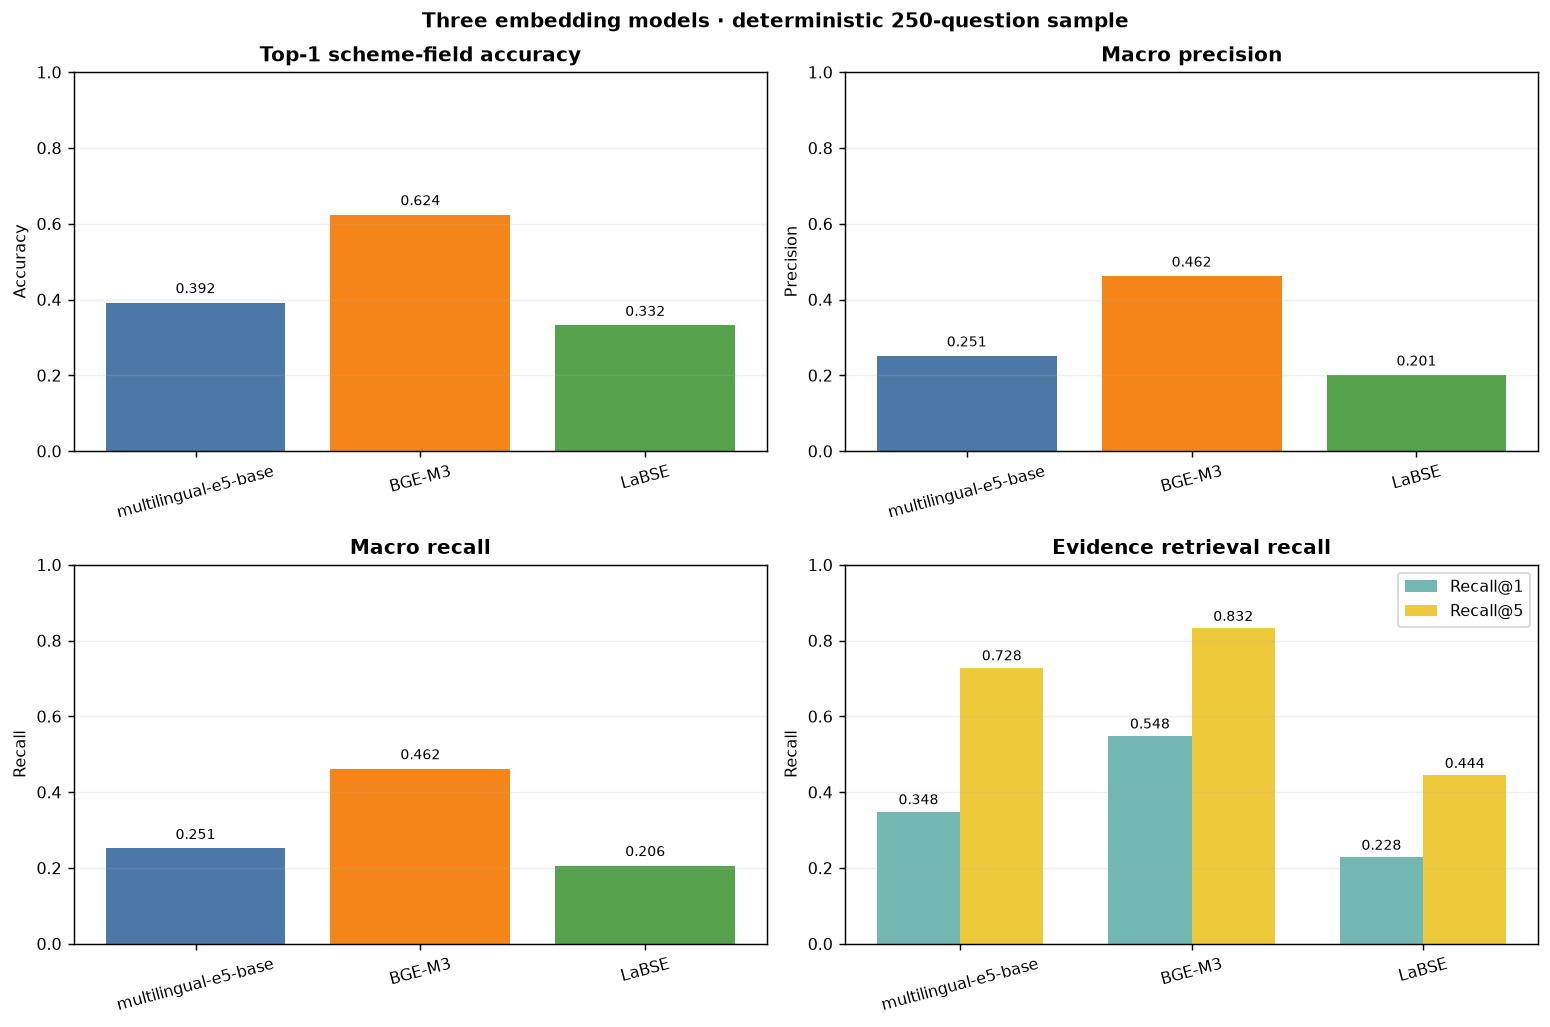

In [5]:
fig,axes=plt.subplots(2,2,figsize=(12,8)); labels=["multilingual-e5-base","BGE-M3","LaBSE"]; colors=["#4c78a8","#f58518","#54a24b"]
def bars(ax,values,title,ylabel):
    b=ax.bar(labels,values,color=colors); ax.set(title=title,ylabel=ylabel,ylim=(0,1)); ax.grid(axis="y",alpha=.2); ax.tick_params(axis="x",rotation=15)
    for bar,v in zip(b,values): ax.text(bar.get_x()+bar.get_width()/2,v+.025,f"{v:.3f}",ha="center",fontsize=8)
bars(axes[0,0],metrics.scheme_field_accuracy,"Top-1 scheme-field accuracy","Accuracy")
bars(axes[0,1],metrics.macro_precision,"Macro precision","Precision")
bars(axes[1,0],metrics.macro_recall,"Macro recall","Recall")
x=range(len(metrics)); w=.36
b1=axes[1,1].bar([i-w/2 for i in x],metrics.retrieval_recall_at_1,w,label="Recall@1",color="#72b7b2")
b5=axes[1,1].bar([i+w/2 for i in x],metrics.retrieval_recall_at_5,w,label="Recall@5",color="#eeca3b")
axes[1,1].set_xticks(list(x),labels,rotation=15); axes[1,1].set(ylim=(0,1),title="Evidence retrieval recall",ylabel="Recall"); axes[1,1].legend(); axes[1,1].grid(axis="y",alpha=.2)
for group in [b1,b5]:
    for bar in group: axes[1,1].text(bar.get_x()+bar.get_width()/2,bar.get_height()+.02,f"{bar.get_height():.3f}",ha="center",fontsize=8)
fig.suptitle("Three embedding models · deterministic 250-question sample",fontweight="bold"); fig.tight_layout(); fig.savefig(REPORTS/"model_metrics.png",bbox_inches="tight"); plt.show()
print(f"Three-model RRF accuracy: {float(ensemble.ensemble_accuracy):.3f}; coverage: {float(ensemble.ensemble_coverage):.3f}")

## Run this notebook

From the project root, install dependencies with `python -m pip install -r requirements-notebook.txt`, then run `jupyter notebook notebooks/government_service_assistant_analysis.ipynb`. It reads CSVs in `data/evaluation/` and saves the diagrams and charts in `reports/`.

The reported measures reflect generated labels and saved benchmark outputs. They do not establish factual correctness. Scheme facts are currently English and should be checked against current official sources.